# Library Import

In [12]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Mount dataset

In [13]:
df = pd.read_csv('../data/Telco-Customer-Churn.csv')
print(df.shape)

(7043, 21)


# Kualitas data

In [14]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Missing per kolom:')
print(df.isna().sum()[df.isna().sum() > 0])
print('Baris duplikat:', df.duplicated().sum())
print('customerID duplikat:', df['customerID'].duplicated().sum())
print(df[df['TotalCharges'].isna()][['tenure', 'Churn']])

Missing per kolom:
TotalCharges    11
dtype: int64
Baris duplikat: 0
customerID duplikat: 0
      tenure Churn
488        0    No
753        0    No
936        0    No
1082       0    No
1340       0    No
3331       0    No
3826       0    No
4380       0    No
5218       0    No
6670       0    No
6754       0    No


# Target dan Statistik Deskriptif

In [15]:
df['y'] = (df['Churn'] == 'Yes').astype(int)
print(df['y'].value_counts(normalize=True))
print(df[['tenure', 'MonthlyCharges', 'TotalCharges']].describe().round(2))
print(df.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].agg(['mean', 'median']).round(2))

y
0    0.73463
1    0.26537
Name: proportion, dtype: float64
        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7032.00
mean     32.37           64.76       2283.30
std      24.56           30.09       2266.77
min       0.00           18.25         18.80
25%       9.00           35.50        401.45
50%      29.00           70.35       1397.48
75%      55.00           89.85       3794.74
max      72.00          118.75       8684.80
      tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2555.34  1683.60
Yes    17.98   10.0          74.44  79.65      1531.80   703.55


# Outlier (IQR)

In [16]:
for c in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    print(c, 'outlier:', n_out, 'skew:', round(df[c].skew(), 2))

tenure outlier: 0 skew: 0.24
MonthlyCharges outlier: 0 skew: -0.22
TotalCharges outlier: 0 skew: 0.96


# Tingkat churn per kategori, kelompok tenure, korelasi

In [17]:
print("===== Tingkat Churn =====\n")
for c in ['Contract', 'InternetService', 'PaymentMethod', 'SeniorCitizen']:
    print(df.groupby(c)['y'].agg(['count', 'mean']).round(3))

print("\n===== Kelompok Tenure =====\n")

df['tenure_group'] = pd.cut(df['tenure'], [-1, 12, 24, 48, 72], labels=['0-12', '13-24', '25-48', '49-72'])
print(df.groupby('tenure_group', observed=True)['y'].agg(['count', 'mean']).round(3))

print("\n===== Korelasi Variabel =====\n")
print(df[['tenure', 'MonthlyCharges', 'TotalCharges', 'y']].corr().round(3))

===== Tingkat Churn =====

                count   mean
Contract                    
Month-to-month   3875  0.427
One year         1473  0.113
Two year         1695  0.028
                 count   mean
InternetService              
DSL               2421  0.190
Fiber optic       3096  0.419
No                1526  0.074
                           count   mean
PaymentMethod                          
Bank transfer (automatic)   1544  0.167
Credit card (automatic)     1522  0.152
Electronic check            2365  0.453
Mailed check                1612  0.191
               count   mean
SeniorCitizen              
0               5901  0.236
1               1142  0.417

===== Kelompok Tenure =====

              count   mean
tenure_group              
0-12           2186  0.474
13-24          1024  0.287
25-48          1594  0.204
49-72          2239  0.095

===== Korelasi Variabel =====

                tenure  MonthlyCharges  TotalCharges      y
tenure           1.000           0.248    

# Visualisasi EDA
grafik disimpan ke folder `figures/` di root repository.

In [18]:
# Pengaturan tema dan folder output
os.makedirs('../figures', exist_ok=True)
sns.set_theme(style='whitegrid')
warna = {'No': '#4C78A8', 'Yes': '#E45756'}
rata_churn = df['y'].mean() * 100

def laju_churn(kolom, label_map=None):
    """Tingkat churn (%) dan jumlah pelanggan per kategori, diurutkan dari terendah."""
    seri = df[kolom].map(label_map) if label_map else df[kolom]
    g = df.groupby(seri)['y'].agg(['mean', 'count'])
    g['mean'] *= 100
    return g.sort_values('mean')

### Distribusi target Churn

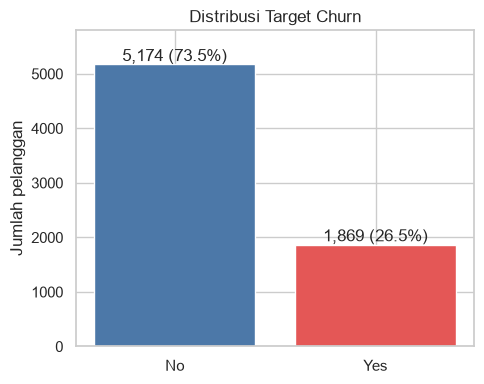

In [19]:
fig, ax = plt.subplots(figsize=(5, 4))
jumlah = df['Churn'].value_counts()
ax.bar(jumlah.index, jumlah.values, color=[warna[k] for k in jumlah.index])
for i, v in enumerate(jumlah.values):
    ax.text(i, v + 60, f'{v:,} ({v / len(df):.1%})', ha='center')
ax.set_ylim(0, jumlah.max() * 1.12)
ax.set_title('Distribusi Target Churn')
ax.set_ylabel('Jumlah pelanggan')
plt.tight_layout()
plt.savefig('../figures/fig1_distribusi_churn.png', dpi=150)
plt.show()

### Distribusi tenure, MonthlyCharges, dan TotalCharges menurut Churn

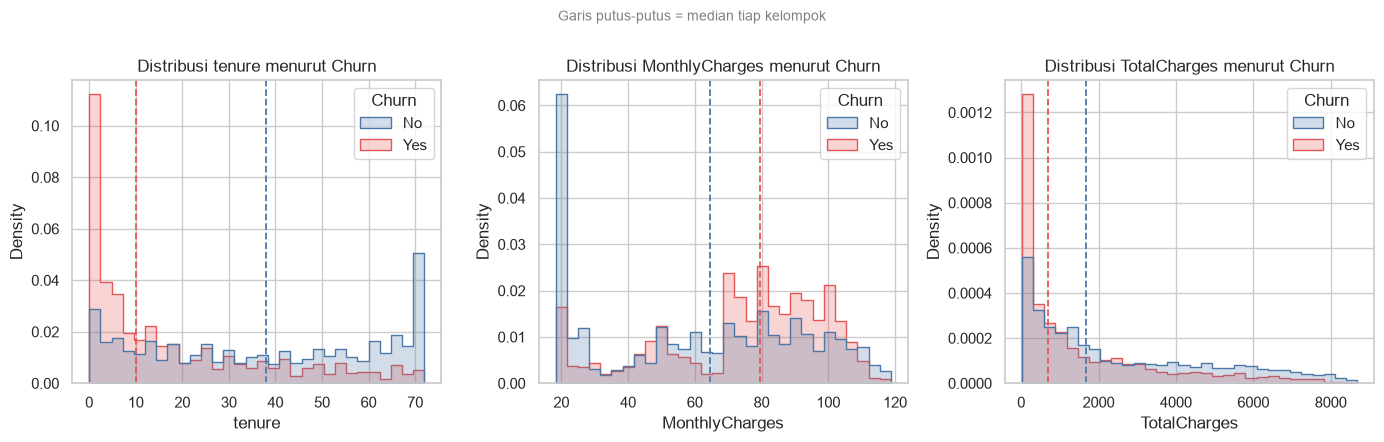

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, c in zip(axes, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    sns.histplot(data=df, x=c, hue='Churn', bins=30, element='step', stat='density', common_norm=False, palette=warna, ax=ax)
    for status, med in df.groupby('Churn')[c].median().items():
        ax.axvline(med, ls='--', lw=1.3, color=warna[status])
    ax.set_title(f'Distribusi {c} menurut Churn')
fig.suptitle('Garis putus-putus = median tiap kelompok', y=1.0, fontsize=10, color='gray')
plt.tight_layout()
plt.savefig('../figures/fig2_distribusi_numerik.png', dpi=150)
plt.show()

### Tingkat churn per kelompok tenure

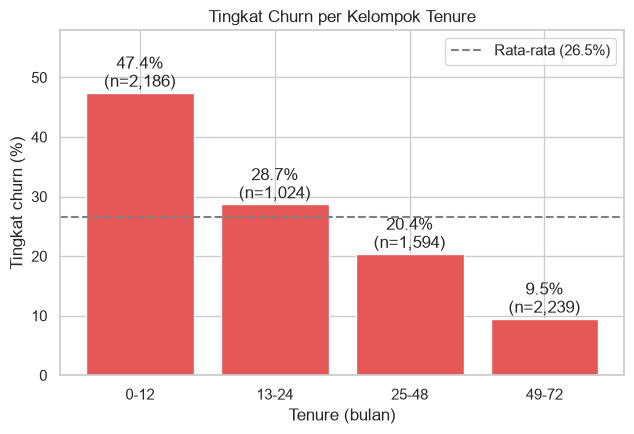

In [21]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
g = df.groupby('tenure_group', observed=True)['y'].agg(['mean', 'count'])
g['mean'] *= 100
ax.bar(g.index.astype(str), g['mean'], color='#E45756')
for i, (v, n) in enumerate(zip(g['mean'], g['count'])):
    ax.text(i, v + 1, f'{v:.1f}%\n(n={n:,})', ha='center')
ax.axhline(rata_churn, ls='--', color='gray', label=f'Rata-rata ({rata_churn:.1f}%)')
ax.set_ylim(0, g['mean'].max() * 1.22)
ax.set_xlabel('Tenure (bulan)')
ax.set_ylabel('Tingkat churn (%)')
ax.set_title('Tingkat Churn per Kelompok Tenure')
ax.legend()
plt.tight_layout()
plt.savefig('../figures/fig3_churn_per_tenure.png', dpi=150)
plt.show()

### Tingkat churn per kategori (6 panel)

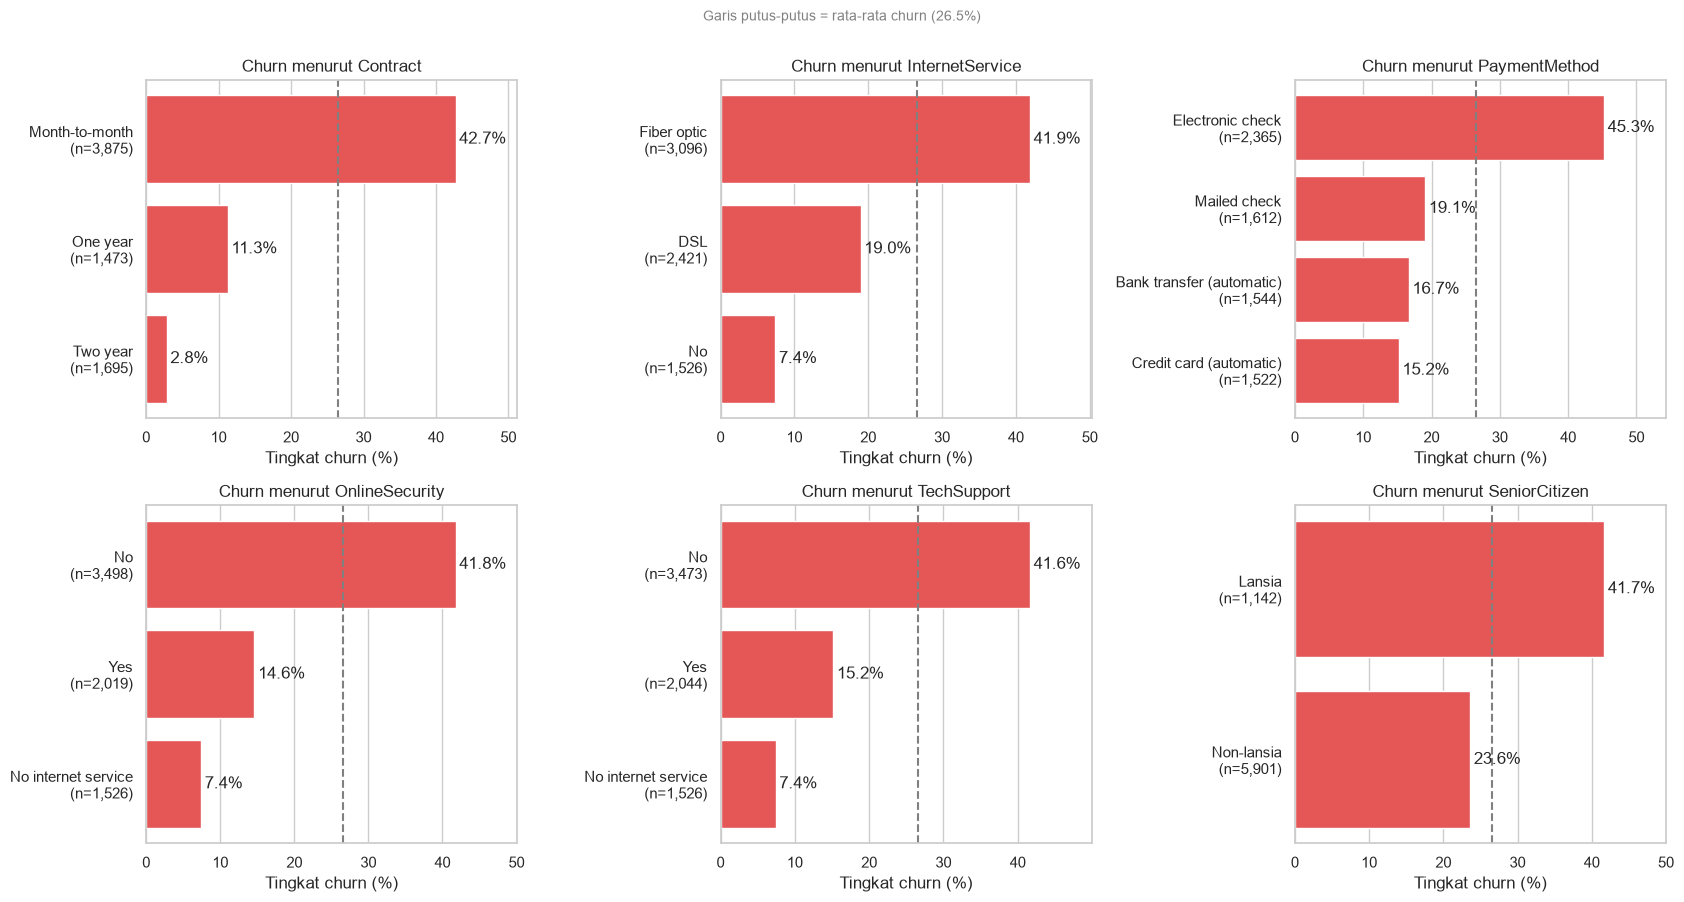

In [22]:
kolom = ['Contract', 'InternetService', 'PaymentMethod', 'OnlineSecurity', 'TechSupport', 'SeniorCitizen']
label_lansia = {0: 'Non-lansia', 1: 'Lansia'}

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, c in zip(axes.ravel(), kolom):
    g = laju_churn(c, label_lansia if c == 'SeniorCitizen' else None)
    ypos = range(len(g))
    ax.barh(ypos, g['mean'], color='#E45756')
    ax.set_yticks(list(ypos))
    ax.set_yticklabels([f'{k}\n(n={n:,})' for k, n in zip(g.index.astype(str), g['count'])])
    for i, v in enumerate(g['mean']):
        ax.text(v + 0.5, i, f'{v:.1f}%', va='center')
    ax.axvline(rata_churn, ls='--', color='gray')
    ax.set_title(f'Churn menurut {c}')
    ax.set_xlabel('Tingkat churn (%)')
    ax.set_xlim(0, g['mean'].max() * 1.2)
    ax.grid(axis='y', visible=False)
fig.suptitle(f'Garis putus-putus = rata-rata churn ({rata_churn:.1f}%)', y=1.0, fontsize=10, color='gray')
plt.tight_layout()
plt.savefig('../figures/fig4_churn_per_kategori.png', dpi=150)
plt.show()

### Heatmap korelasi variabel numerik dan Churn

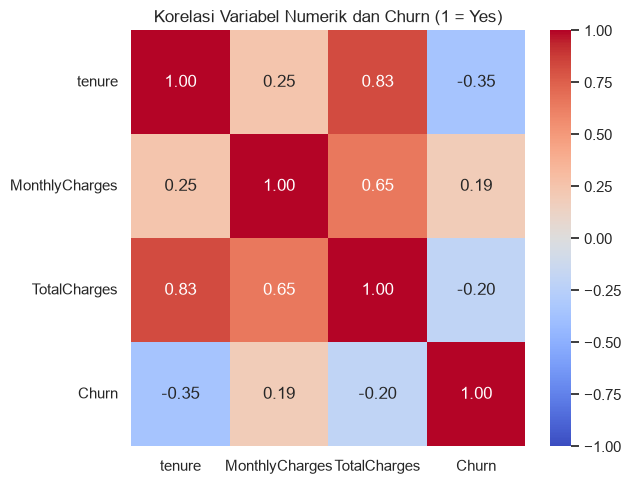

In [23]:
fig, ax = plt.subplots(figsize=(6.5, 5))
korelasi = (df[['tenure', 'MonthlyCharges', 'TotalCharges', 'y']].corr().rename(index={'y': 'Churn'}, columns={'y': 'Churn'}))
sns.heatmap(korelasi, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Korelasi Variabel Numerik dan Churn (1 = Yes)')
plt.tight_layout()
plt.savefig('../figures/fig5_korelasi.png', dpi=150)
plt.show()

### Churn menurut kontrak dan kelompok tenure

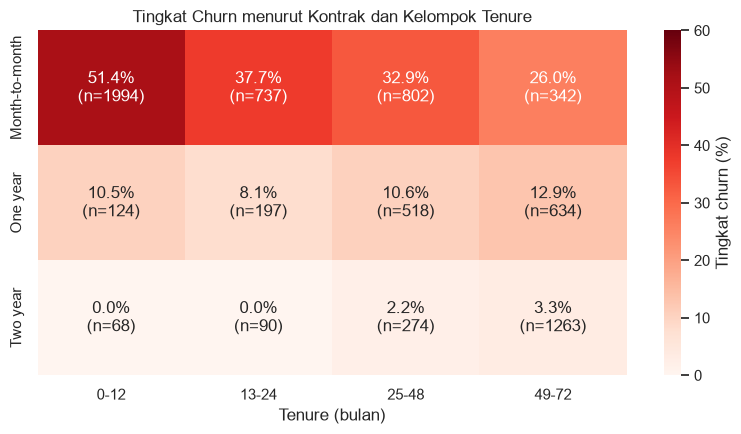

In [24]:
urutan_kontrak = ['Month-to-month', 'One year', 'Two year']
laju = df.pivot_table(index='Contract', columns='tenure_group', values='y', aggfunc='mean', observed=True).reindex(urutan_kontrak) * 100
jumlah = df.pivot_table(index='Contract', columns='tenure_group', values='y', aggfunc='count', observed=True).reindex(urutan_kontrak)
anotasi = laju.round(1).astype(str) + '%\n(n=' + jumlah.astype(int).astype(str) + ')'


fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(laju, annot=anotasi, fmt='', cmap='Reds', vmin=0, vmax=60, cbar_kws={'label': 'Tingkat churn (%)'}, ax=ax)
ax.set_xlabel('Tenure (bulan)')
ax.set_ylabel('')
ax.set_title('Tingkat Churn menurut Kontrak dan Kelompok Tenure')
plt.tight_layout()
plt.savefig('../figures/fig6_churn_kontrak_tenure.png', dpi=150)
plt.show()


### Segmen pelanggan berisiko tinggi

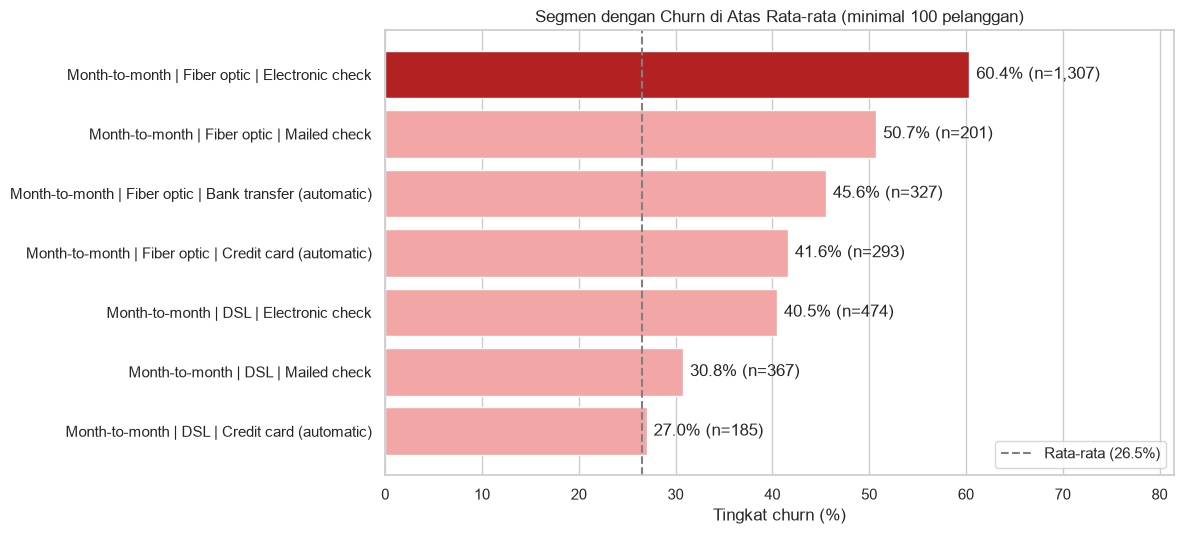

                                                   label  count  mean
         Month-to-month | Fiber optic | Electronic check   1307 0.604
             Month-to-month | Fiber optic | Mailed check    201 0.507
Month-to-month | Fiber optic | Bank transfer (automatic)    327 0.456
  Month-to-month | Fiber optic | Credit card (automatic)    293 0.416
                 Month-to-month | DSL | Electronic check    474 0.405
                     Month-to-month | DSL | Mailed check    367 0.308
          Month-to-month | DSL | Credit card (automatic)    185 0.270


In [25]:
seg = (df.groupby(['Contract', 'InternetService', 'PaymentMethod'])['y'].agg(['mean', 'count']).reset_index())
seg = seg[(seg['count'] >= 100) & (seg['mean'] * 100 > rata_churn)]
seg = seg.sort_values('mean', ascending=False).head(10)
seg['label'] = seg['Contract'] + ' | ' + seg['InternetService'] + ' | ' + seg['PaymentMethod']
seg = seg.iloc[::-1]  # segmen tertinggi di atas


warna_bar = ['#F2A6A5'] * len(seg)
warna_bar[-1] = '#B22222'


fig, ax = plt.subplots(figsize=(12, 5.5))
ax.barh(seg['label'], seg['mean'] * 100, color=warna_bar)
for i, (v, n) in enumerate(zip(seg['mean'] * 100, seg['count'])):
    ax.text(v + 0.7, i, f'{v:.1f}% (n={n:,})', va='center')
ax.axvline(rata_churn, ls='--', color='gray', label=f'Rata-rata ({rata_churn:.1f}%)')
ax.set_xlim(0, (seg['mean'] * 100).max() * 1.35)
ax.set_xlabel('Tingkat churn (%)')
ax.set_title('Segmen dengan Churn di Atas Rata-rata (minimal 100 pelanggan)')
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../figures/fig7_segmen_berisiko.png', dpi=150)
plt.show()
print(seg[['label', 'count', 'mean']].iloc[::-1].round(3).to_string(index=False))


### Tagihan bulanan menurut jenis internet dan status churn

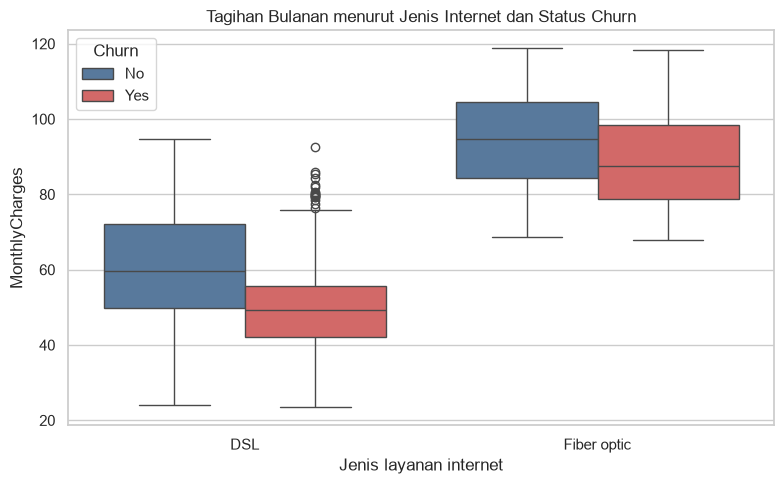

InternetService  Churn
DSL              No       59.8
                 Yes      49.2
Fiber optic      No       94.8
                 Yes      87.6
Name: MonthlyCharges, dtype: float64
                  mean               count            
InternetService    DSL Fiber optic     DSL Fiber optic
rentang                                               
<=50             0.321         NaN   773.0         NaN
50-70            0.163       0.625  1049.0       112.0
70-90            0.071       0.509   552.0      1292.0
>90              0.021       0.336    47.0      1692.0


In [26]:
internet = df[df['InternetService'] != 'No']


fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=internet, x='InternetService', y='MonthlyCharges', hue='Churn', order=['DSL', 'Fiber optic'], hue_order=['No', 'Yes'], palette=warna, ax=ax)
ax.set_xlabel('Jenis layanan internet')
ax.set_ylabel('MonthlyCharges')
ax.set_title('Tagihan Bulanan menurut Jenis Internet dan Status Churn')
plt.tight_layout()
plt.savefig('../figures/fig8_tagihan_per_internet.png', dpi=150)
plt.show()


print(internet.groupby(['InternetService', 'Churn'])['MonthlyCharges'].median().round(1))


# Pembanding: tingkat churn per rentang tagihan, dipisah jenis internet
internet = internet.assign(rentang=pd.cut(internet['MonthlyCharges'], [0, 50, 70, 90, 200], labels=['<=50', '50-70', '70-90', '>90']))
print(internet.pivot_table(index='rentang', columns='InternetService', values='y', aggfunc=['mean', 'count'], observed=True).round(3))